# 01 · Exploratory data analysis

Class balance over time, amount distributions and entity (uid) statistics for the canonical
transaction table.

* **Inputs:** `data/interim/<dataset>/transactions.parquet` from `make features DATASET=<dataset>`.
* **Run:** `make eda DATASET=sparkov` executes this notebook in place (default dataset: `sparkov`).
* All computations live in `fraudshield.eda` (unit-tested); this notebook only calls them and plots.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

from fraudshield.config import get_settings
from fraudshield.eda import (
    amount_summary,
    daily_class_balance,
    new_uid_share_by_day,
    new_vs_known_summary,
    uid_summary,
)
from fraudshield.pipeline import DatasetPaths

# Run from the repo root so configs/ and data/ resolve (Jupyter starts in notebooks/).
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()))
settings = get_settings()
DATASET = settings.dataset
ds = settings.datasets.get(DATASET)
df = pl.read_parquet(DatasetPaths.of(settings, DATASET).canonical)
print(
    f"{DATASET}: {df.height:,} transactions, {df['uid'].n_unique():,} uids, "
    f"{df['event_time'].min()} .. {df['event_time'].max()}"
)

ieee_cis: 590,540 transactions, 217,850 uids, 2017-12-02 00:00:00+00:00 .. 2018-06-01 23:58:51+00:00


## Class balance over time
Shaded bands are the configured train / val / test windows; gaps between them are the label-delay gaps.

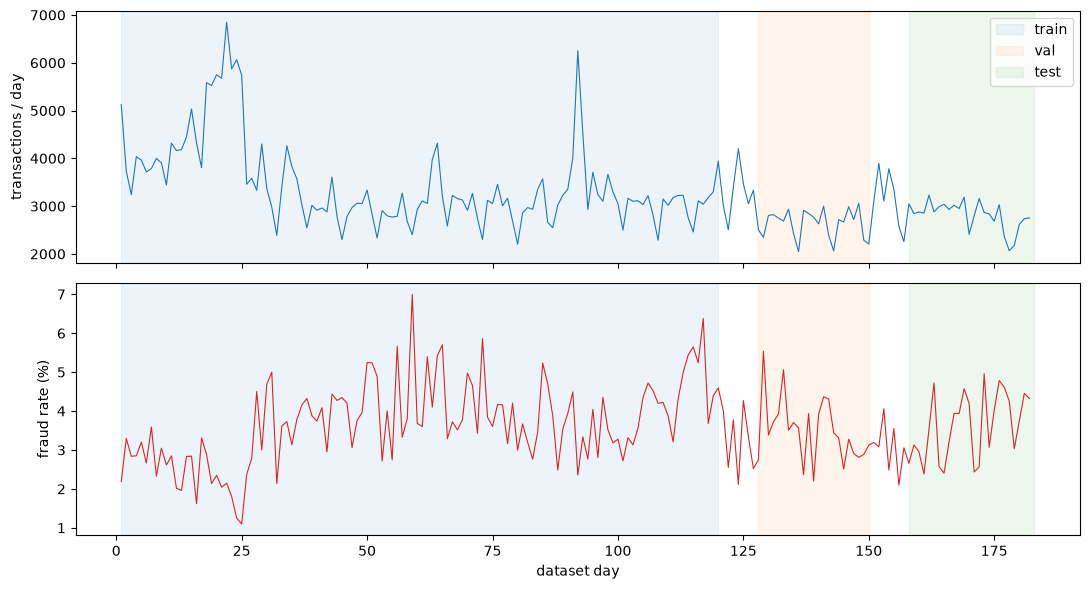

In [2]:
daily = daily_class_balance(df, ds.origin)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.plot(daily["day"], daily["n"], lw=0.8)
ax1.set_ylabel("transactions / day")
ax2.plot(daily["day"], daily["fraud_rate"] * 100, lw=0.8, color="tab:red")
ax2.set_ylabel("fraud rate (%)")
ax2.set_xlabel("dataset day")
for name, r, c in (
    ("train", ds.splits.train, "tab:blue"),
    ("val", ds.splits.val, "tab:orange"),
    ("test", ds.splits.test, "tab:green"),
):
    for ax in (ax1, ax2):
        ax.axvspan(r.start, r.end, alpha=0.08, color=c, label=name if ax is ax1 else None)
ax1.legend(loc="upper right")
plt.tight_layout()

In [3]:
split_of = {"train": ds.splits.train, "val": ds.splits.val, "test": ds.splits.test}
pl.DataFrame(
    [
        {
            "split": s,
            "days": r.n_days,
            **daily.filter(pl.col("day").is_between(r.start, r.end))
            .select(n=pl.col("n").sum(), n_fraud=pl.col("n_fraud").sum())
            .row(0, named=True),
        }
        for s, r in split_of.items()
    ]
).with_columns(fraud_rate=pl.col("n_fraud") / pl.col("n"))

split,days,n,n_fraud,fraud_rate
str,i64,i64,i64,f64
"""train""",120,414542,14600,0.03522
"""val""",23,60602,2114,0.034883
"""test""",26,70356,2532,0.035988


## Amount distributions

In [4]:
amount_summary(df)

label,n,mean,p50,p90,p99,max
i8,u32,f64,f64,f64,f64,f64
0,569877,134.511665,68.5,267.08,1104.0,31937.391
1,20663,149.244779,75.0,335.0,994.0,5191.0


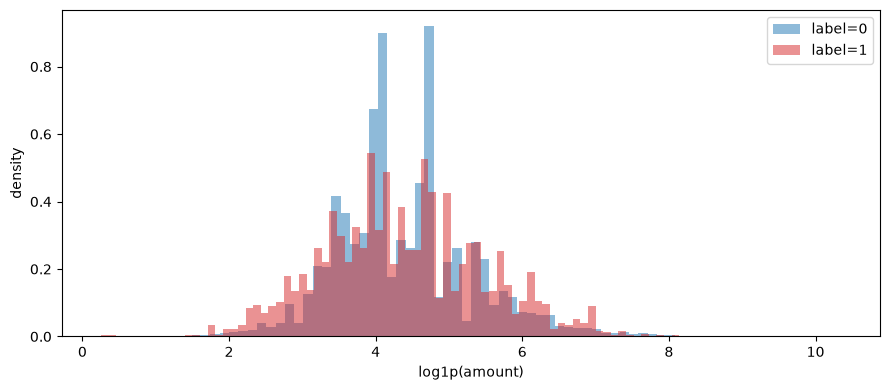

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for label, color in ((0, "tab:blue"), (1, "tab:red")):
    a = df.filter(pl.col("label") == label)["amount"].log1p()
    ax.hist(a, bins=80, density=True, alpha=0.5, color=color, label=f"label={label}")
ax.set_xlabel("log1p(amount)")
ax.set_ylabel("density")
ax.legend()
plt.tight_layout()

## Entity (uid) statistics

In [6]:
uid_summary(df)

n_uids,txns_per_uid_p50,txns_per_uid_p90,txns_per_uid_max,share_uids_with_fraud,single_txn_uid_share
u32,f64,f64,u32,f64,f64
217850,1.0,6.0,1414,0.037255,0.574808


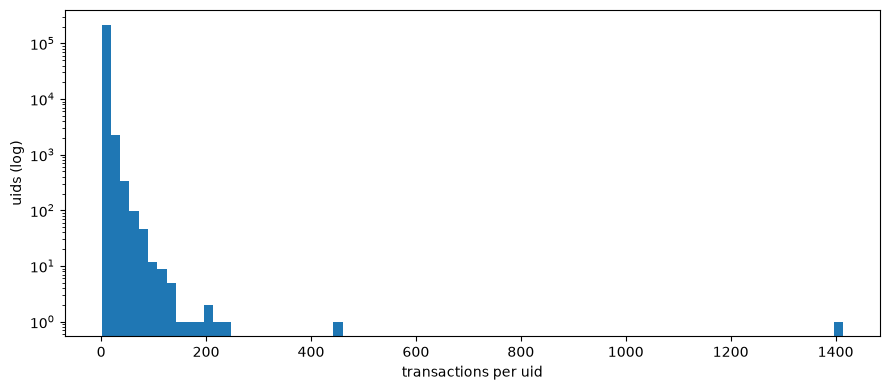

In [7]:
per_uid = df.group_by("uid").agg(n=pl.len())
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(per_uid["n"], bins=80, log=True)
ax.set_xlabel("transactions per uid")
ax.set_ylabel("uids (log)")
plt.tight_layout()

## New vs known uids
Share of each day's transactions that are a uid's first event, and fraud rates for new vs known uids (motivates the new/known evaluation split in Phase 2).

segment,n,n_fraud,share,fraud_rate
str,u32,i64,f64,f64
"""new""",217850,6044,0.3689,0.027744
"""known""",372690,14619,0.6311,0.039226


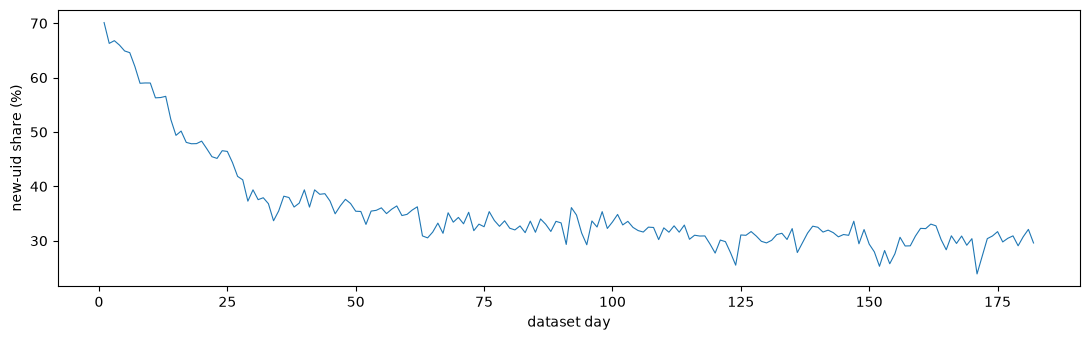

In [8]:
new = new_uid_share_by_day(df, ds.origin)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(new["day"], new["new_share"] * 100, lw=0.8)
ax.set_ylabel("new-uid share (%)")
ax.set_xlabel("dataset day")
plt.tight_layout()
new_vs_known_summary(df)